In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [27]:
rated_mw = 2.3                                     # rated power of one turbine (MW)
blue, orange, aqua, yellow = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
grey = "#9a9a9a"

sns.set_theme(
    style="whitegrid",
    palette=[blue, orange, aqua, yellow],
    rc={
        "axes.facecolor": "#eeeeee",                # light grey plot background
        "figure.facecolor": "white",
        "grid.color": "white", "grid.linewidth": 0.9,
        "axes.spines.left": False, "axes.spines.right": False,     # no frame around the plot
        "axes.spines.top": False, "axes.spines.bottom": False,
        "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlepad": 10,
        "axes.labelsize": 12, "axes.labelcolor": "#333333",
        "xtick.labelsize": 10, "ytick.labelsize": 10,
        "xtick.color": "#555555", "ytick.color": "#555555",
        "legend.frameon": False, "legend.fontsize": 10,
        "figure.dpi": 110, "figure.constrained_layout.use": True,
    },
)

In [ ]:
df= pd.read_parquet("../data/ds4ml/df4ml.parquet")

# one time convention for the whole notebook: tz-aware UTC
df["run_init"] = pd.to_datetime(df["run_init"], utc=True)
df["forecast_time"] = pd.to_datetime(df["forecast_time"], utc=True)
n_turb = df["StationId"].nunique()
farm_mw = n_turb * rated_mw


def scores(obs, pred):
    """Bias, MAE, RMSE and correlation (error = prediction - observation)."""
    o, p = np.asarray(obs, float), np.asarray(pred, float)
    m = ~np.isnan(o) & ~np.isnan(p)
    e = p[m] - o[m]
    return pd.Series({"n": int(m.sum()), "bias": e.mean(), "MAE": np.abs(e).mean(),
                      "RMSE": np.sqrt((e ** 2).mean()), "corr": np.corrcoef(o[m], p[m])[0, 1]})


def fit_curve(wind, power, step=0.5, min_n=20):
    """Empirical power curve: median power per wind bin. Returns a function wind -> power."""
    g = pd.DataFrame({"w": np.asarray(wind, float), "p": np.asarray(power, float)}).dropna()
    bins = np.arange(0, 30 + step, step)
    st = g.groupby(pd.cut(g["w"], bins), observed=False)["p"].agg(["median", "count"])
    ok = (st["count"] >= min_n).to_numpy()
    x, y = ((bins[:-1] + bins[1:]) / 2)[ok], st["median"].to_numpy()[ok]
    return lambda w: np.interp(np.asarray(w, float), x, y)

In [29]:
# ---- 1. missing forecast steps per turbine and run ----------------------------------
steps = np.sort(df["fcst_step"].unique())
n_steps = len(steps)
turbines = np.sort(df["StationId"].unique())
run_hours = sorted(int(h) for h in df["run_init"].dt.hour.unique())

# every run that should exist between the first and the last one (also runs missing completely)
days = pd.date_range(df["run_init"].min().normalize(), df["run_init"].max().normalize(), freq="D")
all_runs = pd.DatetimeIndex([d + pd.Timedelta(hours=h) for d in days for h in run_hours])
all_runs = all_runs[all_runs <= df["run_init"].max()]

present = (df.groupby(["run_init", "StationId"]).size()
             .unstack("StationId")
             .reindex(index=all_runs, columns=turbines)
             .fillna(0))
missing = n_steps - present                         # rows = runs, columns = turbines

summary = pd.DataFrame({
    "missing_steps": missing.sum(),
    "missing_%": missing.sum() / (n_steps * len(all_runs)) * 100,
    "runs_with_gaps": (missing > 0).sum(),
    "runs_fully_missing": (missing == n_steps).sum(),
    "NaN_wind_act": df["wind_act"].isna().groupby(df["StationId"]).sum(),
    "NaN_E_MWh": df["E_MWh"].isna().groupby(df["StationId"]).sum(),
}).sort_values("missing_steps", ascending=False)

n_runs_absent = len(all_runs.difference(pd.DatetimeIndex(df["run_init"].unique())))
print(f"runs: {len(all_runs):,} expected, {df['run_init'].nunique():,} present, "
      f"{n_runs_absent:,} missing for all turbines")
print(f"steps per run: {n_steps} ({steps.min()}-{steps.max()} h), turbines: {len(turbines)}")
summary.round(2)

runs: 1,516 expected, 1,487 present, 29 missing for all turbines
steps per run: 49 (0-48 h), turbines: 21


,missing_steps,missing_%,runs_with_gaps,runs_fully_missing,NaN_wind_act,NaN_E_MWh
StationId,,,,,,
2304525,33730.0,45.41,1516,62,0,0
2304526,29271.0,39.40,1516,50,0,0
2304527,24791.0,33.37,1516,46,0,0
2304520,21903.0,29.49,1516,46,0,0
2304528,20880.0,28.11,1516,38,0,0
2304524,16266.0,21.90,1516,47,0,0
2304530,15822.0,21.30,1516,69,0,0
2304529,15589.0,20.99,1516,33,0,0
2304514,15501.0,20.87,1516,38,0,0


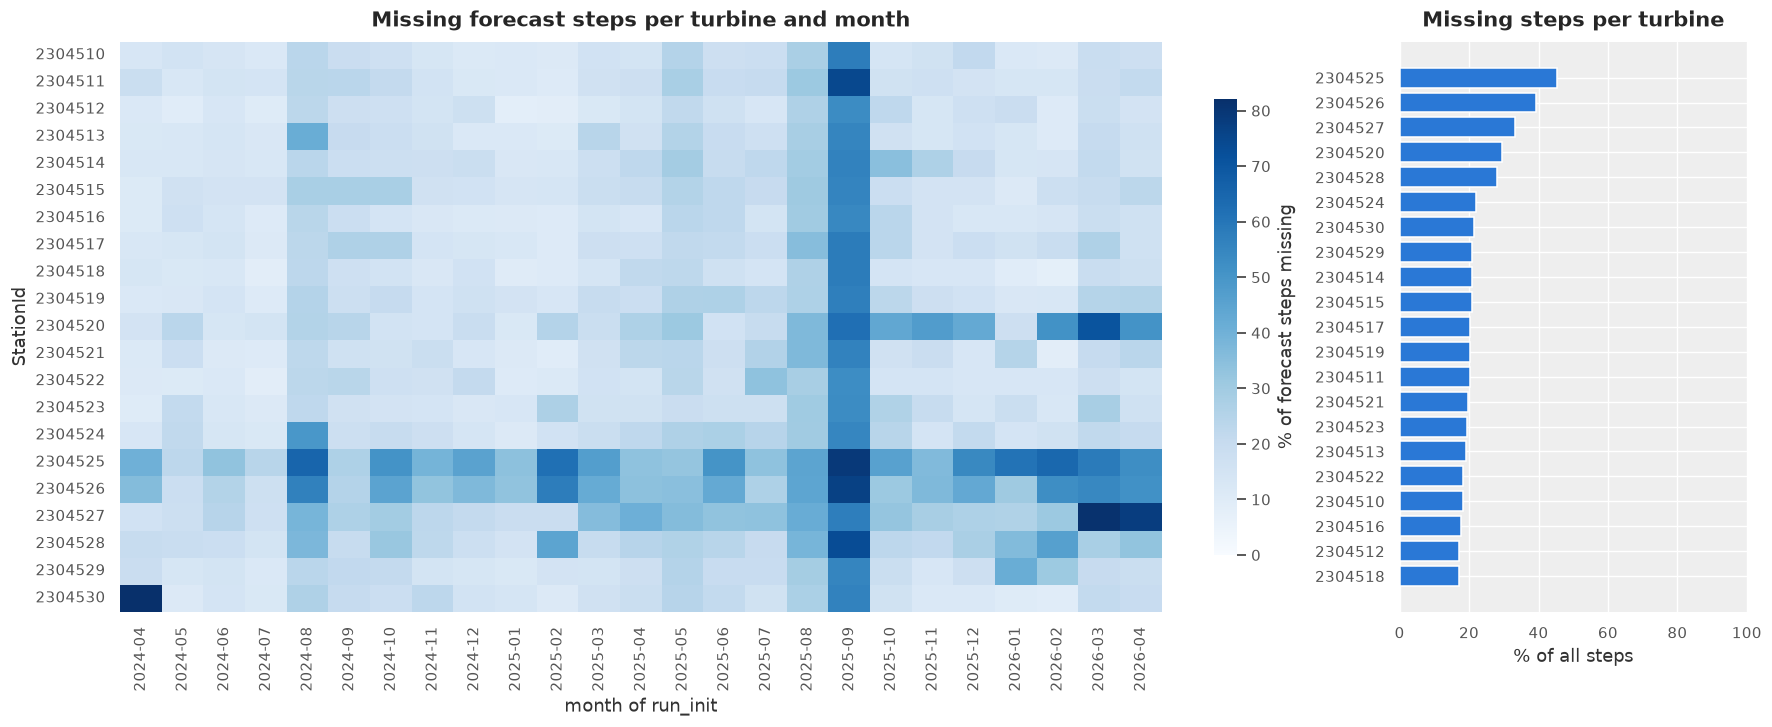

In [30]:
miss_month = missing.groupby(missing.index.strftime("%Y-%m")).mean() / n_steps * 100   # % of steps

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(miss_month.T, cmap="Blues", vmin=0, ax=axes[0],
            cbar_kws={"label": "% of forecast steps missing", "shrink": 0.8})
axes[0].set(title="Missing forecast steps per turbine and month", xlabel="month of run_init", ylabel="StationId")

s = summary["missing_%"].sort_values()
axes[1].barh(s.index.astype(str), s.values, color=blue)
axes[1].set_xlim(0,100)
axes[1].set(title="Missing steps per turbine", xlabel="% of all steps", ylabel="")
plt.show()

In [32]:
# The same measured hour is repeated for every run and step that forecasts it, so the
# observations are de-duplicated first.
# Note: shear_alpha and ws_hub are NOT observations - they are computed from the NWP 10 m / 80 m wind.
obs_cols = ["wind_act", "wd_act", "wind_mean", "E_MWh", "u_mean", "v_mean", "wd_mean"]
obs = (df.drop_duplicates(["forecast_time", "StationId"])[["forecast_time", "StationId"] + obs_cols]
         .sort_values(["StationId", "forecast_time"]).reset_index(drop=True))

# farm level: mean over the turbines in each hour, direction from the mean u, v components
farm = obs.groupby("forecast_time").agg(
    wind=("wind_act", "mean"), E_turb=("E_MWh", "mean"),
    u=("u_mean", "mean"), v=("v_mean", "mean"), n_turb=("StationId", "size"))
farm["wd"] = np.degrees(np.arctan2(-farm["u"], -farm["v"])) % 360
farm["E_farm"] = farm["E_turb"] * n_turb            # MWh per hour, scaled to all turbines

print(f"{len(obs):,} turbine-hours, {len(farm):,} farm hours "
      f"({farm.index.min():%Y-%m-%d} to {farm.index.max():%Y-%m-%d})")
obs[obs_cols].describe().T.round(3)

297,721 turbine-hours, 16,600 farm hours (2024-04-01 to 2026-04-30)


,count,mean,std,min,25%,50%,75%,max
wind_act,297721.0,6.811,3.671,0.010,4.201,6.328,8.930,26.466
wd_act,297721.0,210.253,83.233,0.001,154.330,225.533,269.084,360.000
wind_mean,297721.0,6.818,3.571,0.108,4.280,6.372,8.912,25.953
E_MWh,297721.0,0.633,0.685,-0.018,0.083,0.366,1.015,2.300
u_mean,297721.0,2.202,5.355,-22.916,-1.297,2.122,5.908,25.446
v_mean,297721.0,1.625,4.756,-21.586,-1.289,1.700,4.714,23.704
wd_mean,297721.0,210.549,83.021,0.006,155.008,225.897,269.036,359.999


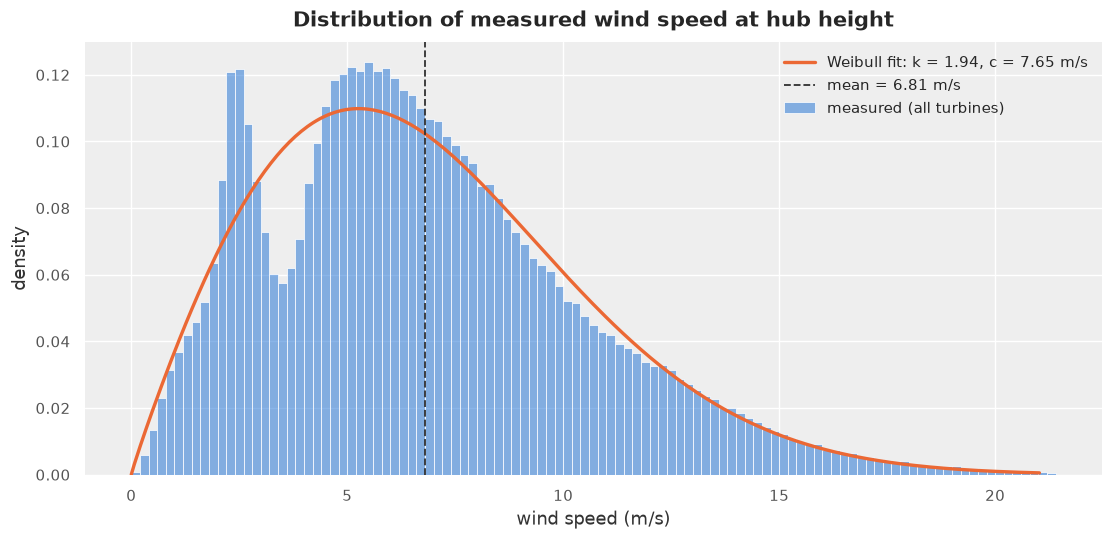

In [ ]:
w = obs["wind_act"].dropna()
w = w[w > 0]
k, _, c = stats.weibull_min.fit(w.sample(min(len(w), 50_000), random_state=0), floc=0)

fig, ax = plt.subplots(figsize=(10, 4.8))
x_max = w.quantile(0.999)
sns.histplot(w, bins=np.arange(0, x_max + 0.5, 0.2), stat="density", color=blue, alpha=0.55,
             edgecolor="white", ax=ax, label="measured (all turbines)")
x = np.linspace(0, x_max, 300)
ax.plot(x, stats.weibull_min.pdf(x, k, 0, c), color=orange, lw=2.2,
        label=f"Weibull fit: k = {k:.2f}, c = {c:.2f} m/s")
ax.axvline(w.mean(), color="#333333", lw=1.2, ls="--", label=f"mean = {w.mean():.2f} m/s")
ax.set(title="Distribution of measured wind speed at hub height", xlabel="wind speed (m/s)",
       ylabel="density")
ax.legend()
plt.show()

In [38]:
df.columns

Index(['run_init', 'forecast_time', 'temperature_2m', 'wind_speed_10m',
       'wind_speed_80m', 'wind_direction_10m', 'wind_direction_80m',
       'fcst_step', 'StationId', 'wind_act', 'wd_act', 'wind_mean', 'E_MWh',
       'u_mean', 'v_mean', 'wd_mean', 'shear_alpha', 'ws_hub'],
      dtype='str')

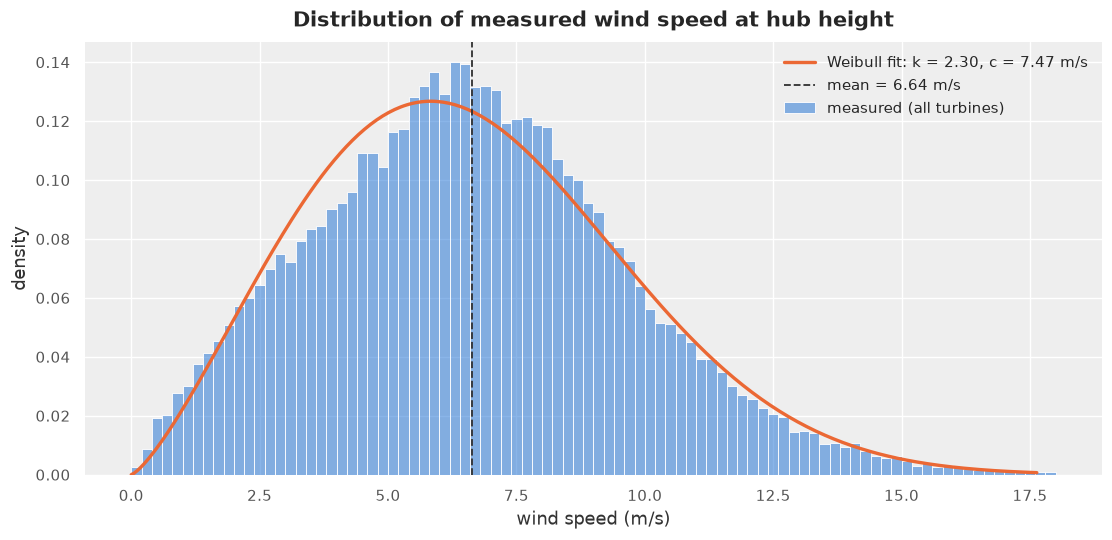

In [39]:
w = df["ws_hub"].dropna()
w = w[w > 0]
k, _, c = stats.weibull_min.fit(w.sample(min(len(w), 50_000), random_state=0), floc=0)

fig, ax = plt.subplots(figsize=(10, 4.8))
x_max = w.quantile(0.999)
sns.histplot(w, bins=np.arange(0, x_max + 0.5, 0.2), stat="density", color=blue, alpha=0.55,
             edgecolor="white", ax=ax, label="measured (all turbines)")
x = np.linspace(0, x_max, 300)
ax.plot(x, stats.weibull_min.pdf(x, k, 0, c), color=orange, lw=2.2,
        label=f"Weibull fit: k = {k:.2f}, c = {c:.2f} m/s")
ax.axvline(w.mean(), color="#333333", lw=1.2, ls="--", label=f"mean = {w.mean():.2f} m/s")
ax.set(title="Distribution of measured wind speed at hub height", xlabel="wind speed (m/s)",
       ylabel="density")
ax.legend()
plt.show()

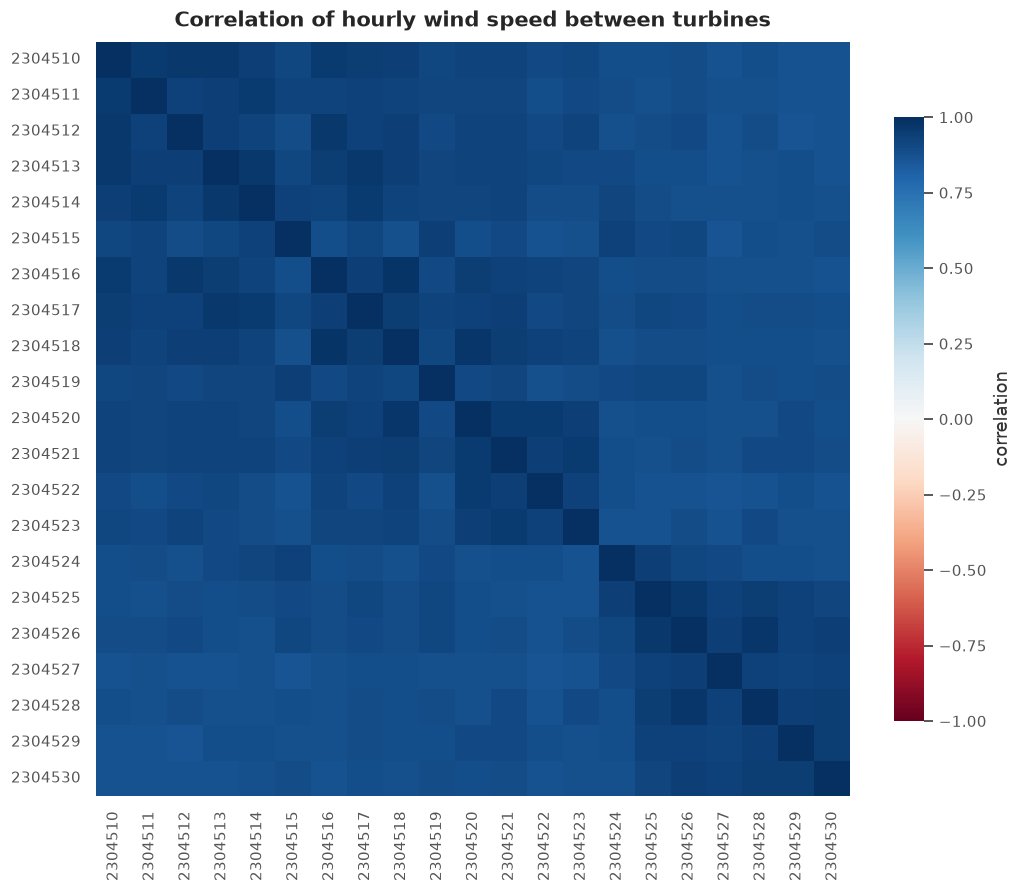

Turbines with the lowest mean correlation to the others:
StationId
2304527    0.891
2304530    0.894
2304524    0.895
2304529    0.897
2304522    0.898


In [42]:
#5. how similar is the wind at the turbines?

wide = obs.pivot_table(index="forecast_time", columns="StationId", values="wind_act")
corr = wide.corr()

fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(corr, cmap="RdBu", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "correlation", "shrink": 0.8}, ax=ax)
ax.set(title="Correlation of hourly wind speed between turbines", xlabel="", ylabel="")
plt.show()

print("Turbines with the lowest mean correlation to the others:")
print(((corr.sum() - 1) / (len(corr) - 1)).sort_values().head(5).round(3).to_string())

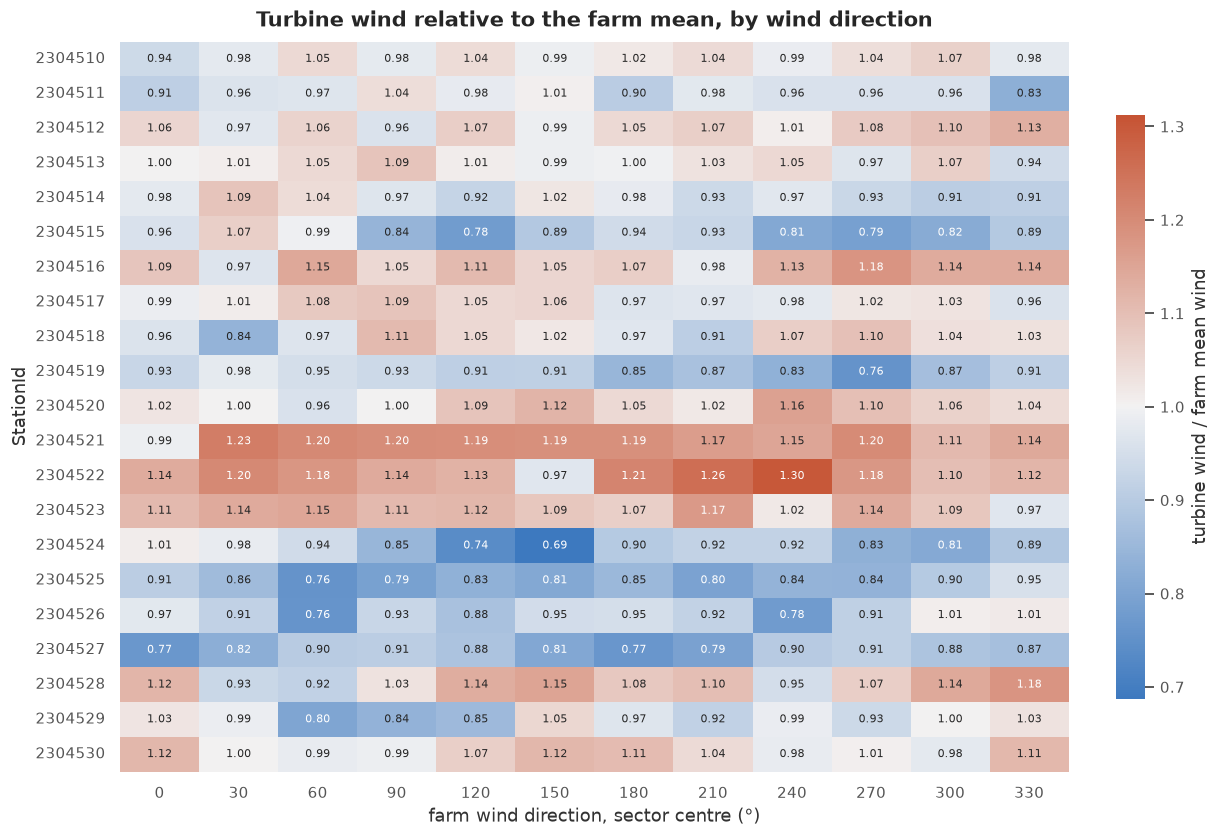

In [43]:
#6. speed-up and wakes: turbine wind relative to the farm mean, by direction

sector = 30
rel = obs.join(farm[["wind", "wd"]], on="forecast_time")
rel = rel[rel["wind"].between(4, 15)]                         # enough wind, below cut-out
rel["sector"] = ((rel["wd"] + sector / 2) // sector % (360 // sector) * sector).astype(int)
rel["ratio"] = rel["wind_act"] / rel["wind"]
hm = rel.pivot_table(index="StationId", columns="sector", values="ratio", aggfunc="median")

v = max(0.05, np.nanmax(np.abs(hm.to_numpy() - 1)))
fig, ax = plt.subplots(figsize=(11, 7.5))
sns.heatmap(hm, cmap=sns.diverging_palette(250, 20, s=80, l=50, center="light", as_cmap=True),
            center=1, vmin=1 - v, vmax=1 + v, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "turbine wind / farm mean wind", "shrink": 0.8}, ax=ax)
ax.set(title="Turbine wind relative to the farm mean, by wind direction",
       xlabel="farm wind direction, sector centre (°)", ylabel="StationId")
plt.show()

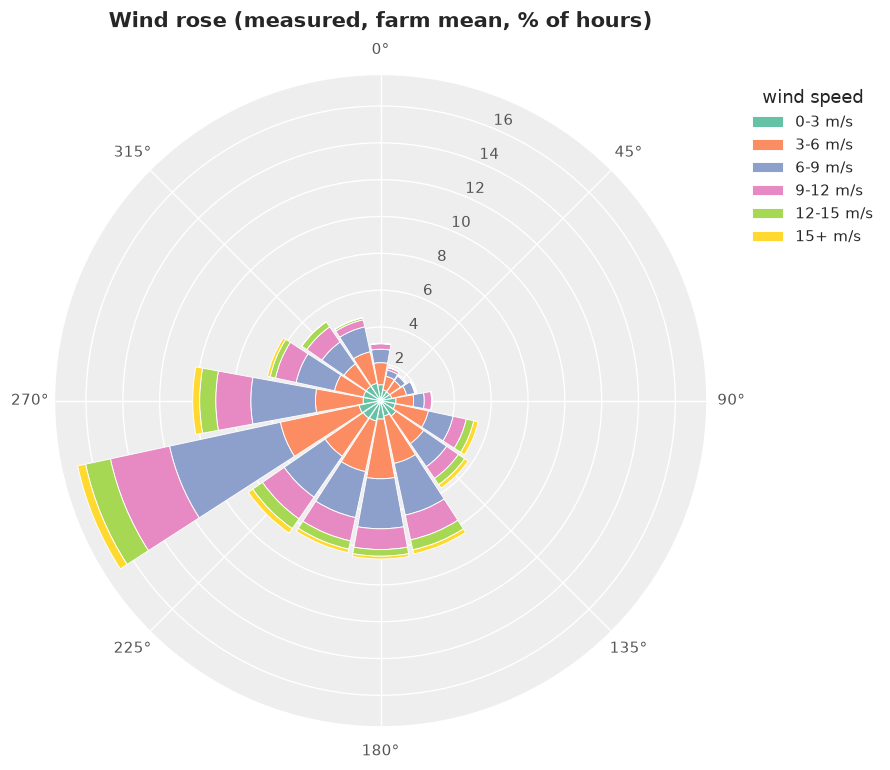

In [53]:
#7. wind rose: direction and speed (measured, farm mean)

n_sec = 16
width = 360 / n_sec
speed_bins = [0, 3, 6, 9, 12, 15, np.inf]
speed_labels = ["0-3", "3-6", "6-9", "9-12", "12-15", "15+"]

d = farm.dropna(subset=["wind", "wd"])
sec = ((d["wd"] + width / 2) // width % n_sec).astype(int)
cls = pd.cut(d["wind"], speed_bins, labels=speed_labels, right=False)
tab = (pd.crosstab(sec, cls, normalize=True) * 100).reindex(index=range(n_sec), columns=speed_labels,
                                                            fill_value=0)

theta = np.radians(np.arange(n_sec) * width)
fig = plt.figure(figsize=(8, 7.5))
ax = fig.add_subplot(projection="polar")
bottom = np.zeros(n_sec)
for lab, col in zip(speed_labels, sns.color_palette("Set2", len(speed_labels))):
    vals = tab[lab].to_numpy()
    ax.bar(theta, vals, width=np.radians(width) * 0.92, bottom=bottom, color=col,
           edgecolor="white", linewidth=0.6, label=f"{lab} m/s")
    bottom += vals
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.spines["polar"].set_visible(False)              # no outer frame, like the other plots
ax.set_title("Wind rose (measured, farm mean, % of hours)")
ax.legend(title="wind speed", loc="upper left", bbox_to_anchor=(1.05, 1.0))
plt.show()

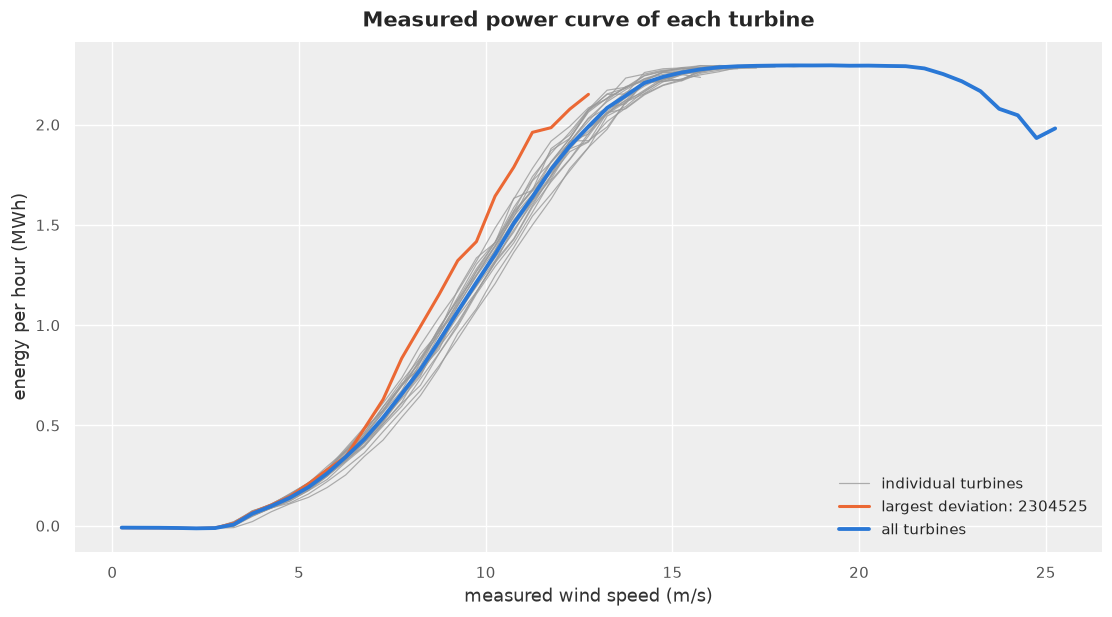

In [55]:
#8. power curve of every turbine (measured wind -> energy) ------------------------------
bins = np.arange(0, 26, 0.5)
mids = (bins[:-1] + bins[1:]) / 2
obs_b = obs.assign(wbin=pd.cut(obs["wind_act"], bins, labels=mids))
pc = obs_b.groupby(["StationId", "wbin"], observed=True)["E_MWh"].agg(["median", "count"]).reset_index()
pc = pc[pc["count"] >= 20]
pc["wind"] = pc["wbin"].astype(float)
farm_pc = obs_b.groupby("wbin", observed=True)["E_MWh"].median()
farm_pc.index = farm_pc.index.astype(float)

# turbine furthest from the common curve on the steep part (5-11 m/s)
steep = pc[pc["wind"].between(5, 11)].copy()
steep["dev"] = steep["median"] - np.interp(steep["wind"], farm_pc.index, farm_pc.values)
worst = steep.groupby("StationId")["dev"].mean().abs().idxmax()

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (sid, g) in enumerate(pc.groupby("StationId")):
    ax.plot(g["wind"], g["median"], color=grey, lw=0.8, alpha=0.8,
            label="individual turbines" if i == 0 else None)
g = pc[pc["StationId"] == worst]
ax.plot(g["wind"], g["median"], color=orange, lw=2, label=f"largest deviation: {worst}")
ax.plot(farm_pc.index, farm_pc.values, color=blue, lw=2.5, label="all turbines")
ax.set(title="Measured power curve of each turbine", xlabel="measured wind speed (m/s)",
       ylabel="energy per hour (MWh)")
ax.legend(loc="lower right")
plt.show()

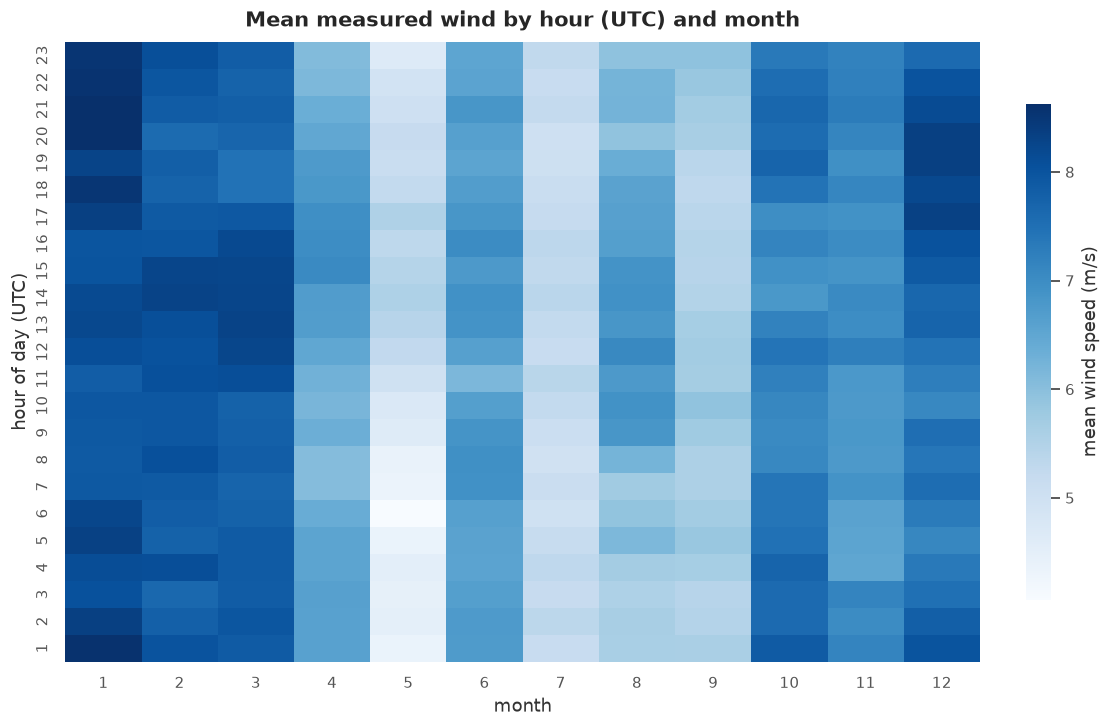

In [56]:
#9. when is it windy? hour of day x month (measured farm mean wind)

hm = (farm.assign(hour=farm.index.hour, month=farm.index.month)
          .pivot_table(index="hour", columns="month", values="wind", aggfunc="mean"))

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(hm, cmap="Blues", cbar_kws={"label": "mean wind speed (m/s)", "shrink": 0.8}, ax=ax)
ax.invert_yaxis()
ax.set(title="Mean measured wind by hour (UTC) and month", xlabel="month", ylabel="hour of day (UTC)")
plt.show()

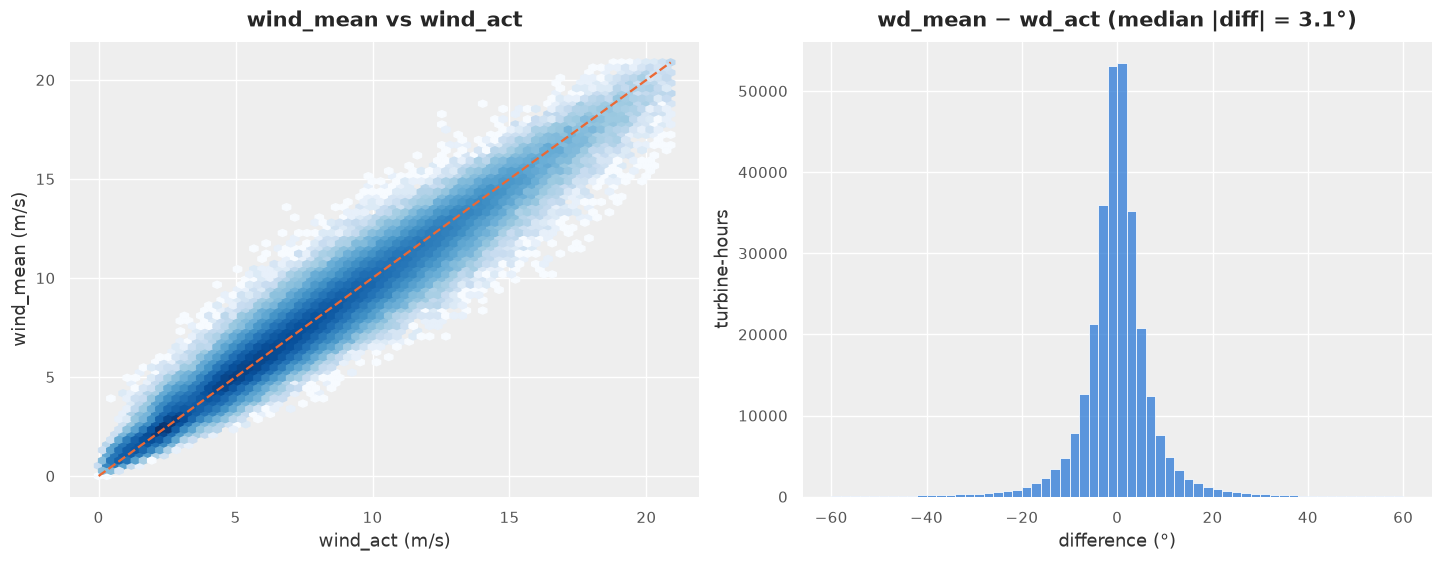

In [58]:
#10. are the two measured wind columns consistent? ----------------------------------------

pair = obs[["wind_act", "wind_mean"]].dropna()
dd = (((obs["wd_mean"] - obs["wd_act"] + 180) % 360) - 180).dropna()
lim = np.nanpercentile(pair.to_numpy(), 99.9)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hexbin(pair["wind_act"], pair["wind_mean"], gridsize=70, bins="log", cmap="Blues", mincnt=1,
               extent=(0, lim, 0, lim))
axes[0].plot([0, lim], [0, lim], color=orange, lw=1.5, ls="--")
axes[0].set(title="wind_mean vs wind_act", xlabel="wind_act (m/s)", ylabel="wind_mean (m/s)")
sns.histplot(dd, bins=np.arange(-60, 61, 2), color=blue, ax=axes[1])
axes[1].set(title=f"wd_mean − wd_act (median |diff| = {dd.abs().median():.1f}°)",
            xlabel="difference (°)", ylabel="turbine-hours")
plt.show()

In [61]:
# 11. baseline models: day-ahead NWP vs measurements
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression

DA_RUN_HOUR, DA_STEPS = 0, (24, 47)       # 00 UTC run of day D-1 -> the 24 hours of day D
MIN_TURB = n_turb - 3                     # use farm hours with at most 3 turbines missing

nwp_cols = ["run_init", "forecast_time", "fcst_step", "temperature_2m", "wind_speed_10m",
            "wind_speed_80m", "wind_direction_80m", "shear_alpha", "ws_hub"]
nwp = df.drop_duplicates(["run_init", "forecast_time"])[nwp_cols]
da = (nwp[(nwp["run_init"].dt.hour == DA_RUN_HOUR) & nwp["fcst_step"].between(*DA_STEPS)]
        .merge(farm.loc[farm["n_turb"] >= MIN_TURB, ["wind", "E_farm"]],
               left_on="forecast_time", right_index=True)
        .dropna(subset=["wind", "E_farm", "ws_hub"])
        .sort_values("forecast_time").reset_index(drop=True))

# features for the ML baseline - all of them are known one day ahead
da["dir_sin"] = np.sin(np.radians(da["wind_direction_80m"]))
da["dir_cos"] = np.cos(np.radians(da["wind_direction_80m"]))
da["hour_sin"] = np.sin(2 * np.pi * da["forecast_time"].dt.hour / 24)
da["hour_cos"] = np.cos(2 * np.pi * da["forecast_time"].dt.hour / 24)
FEATURES = ["ws_hub", "wind_speed_10m", "wind_speed_80m", "shear_alpha", "dir_sin", "dir_cos",
            "temperature_2m", "hour_sin", "hour_cos"]

# split by time (never random): first 70 % train, last 30 % test
t_split = da["forecast_time"].iloc[int(len(da) * 0.7)]
train = da[da["forecast_time"] < t_split]
test = da[da["forecast_time"] >= t_split].copy()
print(f"train: {len(train):,} hours until {t_split:%Y-%m-%d}; test: {len(test):,} hours")

# wind forecasts for the test period
lin = LinearRegression().fit(train[["ws_hub"]], train["wind"])
hgb = HistGradientBoostingRegressor(random_state=0).fit(train[FEATURES], train["wind"])
test["w_raw80"] = test["wind_speed_80m"]
test["w_hub"] = test["ws_hub"]
test["w_lin"] = lin.predict(test[["ws_hub"]])
test["w_ml"] = hgb.predict(test[FEATURES])

# the same power curve for every wind forecast (fitted on the training period, measured wind)
curve = fit_curve(train["wind"], train["E_farm"])
SCEN = {"A: raw NWP 80 m": "w_raw80", "A': NWP at 59 m (power law)": "w_hub",
        "B: linear correction": "w_lin", "C: gradient boosting": "w_ml",
        "D: measured wind (perfect)": "wind"}
rows = {}
for name, col in SCEN.items():
    sw = scores(test["wind"], test[col])
    sp = scores(test["E_farm"], curve(test[col]))
    rows[name] = {"wind bias (m/s)": sw["bias"], "wind MAE (m/s)": sw["MAE"],
                  "power NMAE (%)": sp["MAE"] / farm_mw * 100,
                  "power NRMSE (%)": sp["RMSE"] / farm_mw * 100,
                  "imbalance (MWh)": np.abs(curve(test[col]) - test["E_farm"]).sum()}
results = pd.DataFrame(rows).T
results.round(3)

train: 7,610 hours until 2025-07-12; test: 3,262 hours


,wind bias (m/s),wind MAE (m/s),power NMAE (%),power NRMSE (%),imbalance (MWh)
A: raw NWP 80 m,0.213,1.343,9.599,13.747,15122.916
A': NWP at 59 m (power law),-0.315,1.328,9.291,13.560,14638.462
B: linear correction,-0.072,1.325,9.328,13.371,14696.719
C: gradient boosting,-0.115,1.360,9.852,14.336,15522.013
D: measured wind (perfect),0.000,0.000,3.645,5.661,5743.280


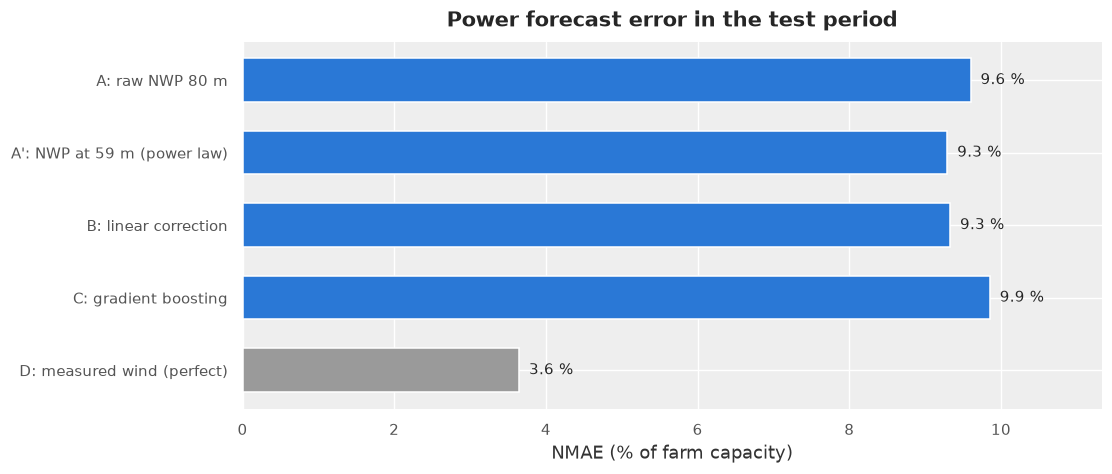

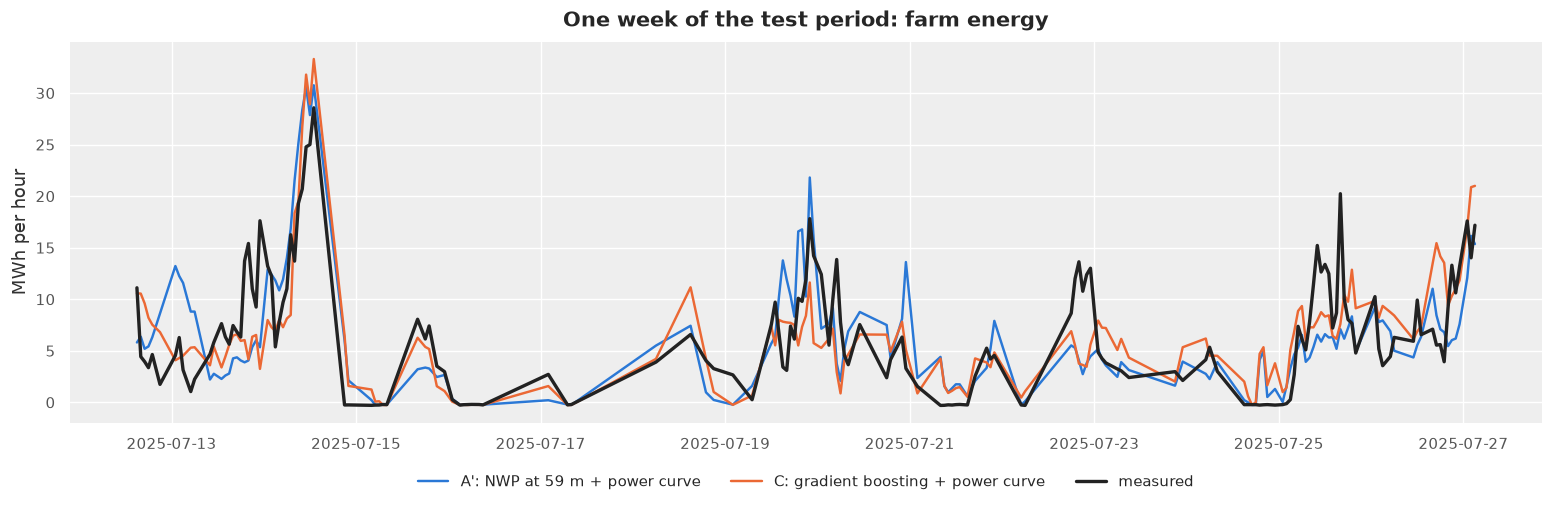

In [64]:
#12. how much does each step help? ------------------------------------------------------------

r = results["power NMAE (%)"][::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(r.index, r.values, color=[grey if name.startswith("D") else blue for name in r.index], height=0.6)
for y, val in enumerate(r.values):
    ax.text(val, y, f"  {val:.1f} %", va="center", fontsize=10)
ax.set(title="Power forecast error in the test period", xlabel="NMAE (% of farm capacity)", ylabel="")
ax.set_xlim(0, r.max() * 1.15)
plt.show()

week = test.set_index("forecast_time").iloc[: 24 * 7]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(week.index, curve(week["w_hub"]), color=blue, lw=1.6, label="A': NWP at 59 m + power curve")
ax.plot(week.index, curve(week["w_ml"]), color=orange, lw=1.6, label="C: gradient boosting + power curve")
ax.plot(week.index, week["E_farm"], color="#222222", lw=2.2, label="measured")
ax.set(title="One week of the test period: farm energy", xlabel="", ylabel="MWh per hour")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()